## Part 1: Import Required Libraries

In [ ]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
import tensorflow as tf
import tensorflow.keras as keras
from keras.models import Sequential
from keras.layers import Dense, Input , Flatten,Conv2D, MaxPooling2D,Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.activations import softmax,relu

## Part 2: Define Dataset Paths

In [4]:
train_path = r"C:\Users\MSI\CNN Assignment\Vegetable Images\train"
test_path = r"C:\Users\MSI\CNN Assignment\Vegetable Images\test"
validation_path = r"C:\Users\MSI\CNN Assignment\Vegetable Images\validation"

## Part 3: Count Images in Each Class

In [5]:
def count_images(dataset_path):
    result = {}
    image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp')

    for class_name in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_name)

        if os.path.isdir(class_path):
            count = 0

            for root, dirs, files in os.walk(class_path):
                for file in files:
                    if file.lower().endswith(image_extensions):
                        count += 1

            result[class_name] = count

    return result

In [6]:
count1 = count_images(os.path.join("Vegetable Images", "test"))
count2 = count_images(os.path.join("Vegetable Images", "train"))
count3 = count_images(os.path.join("Vegetable Images", "validation"))

print("Test:", count1)
print("Train:", count2)
print("Validation:", count3)

Test: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}
Train: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
Validation: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


## Part 4: Create a Summary DataFrame

In [7]:
df_train = pd.DataFrame({
    'Vegetable': count2.keys(),
    'Train Count': count2.values()
})

df_test = pd.DataFrame({
    'Vegetable': count1.keys(),
    'Test Count': count1.values()
})

df_validation = pd.DataFrame({
    'Vegetable': count3.keys(),
    'Validation Count': count3.values()
})

In [8]:
df_final = pd.merge(df_train, df_test, on='Vegetable')
df_final = pd.merge(df_final, df_validation, on='Vegetable')

df_final = df_final[
    ['Vegetable', 'Train Count', 'Test Count', 'Validation Count']
]

display(df_final)

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


## Part 5: Visualize Class Distribution

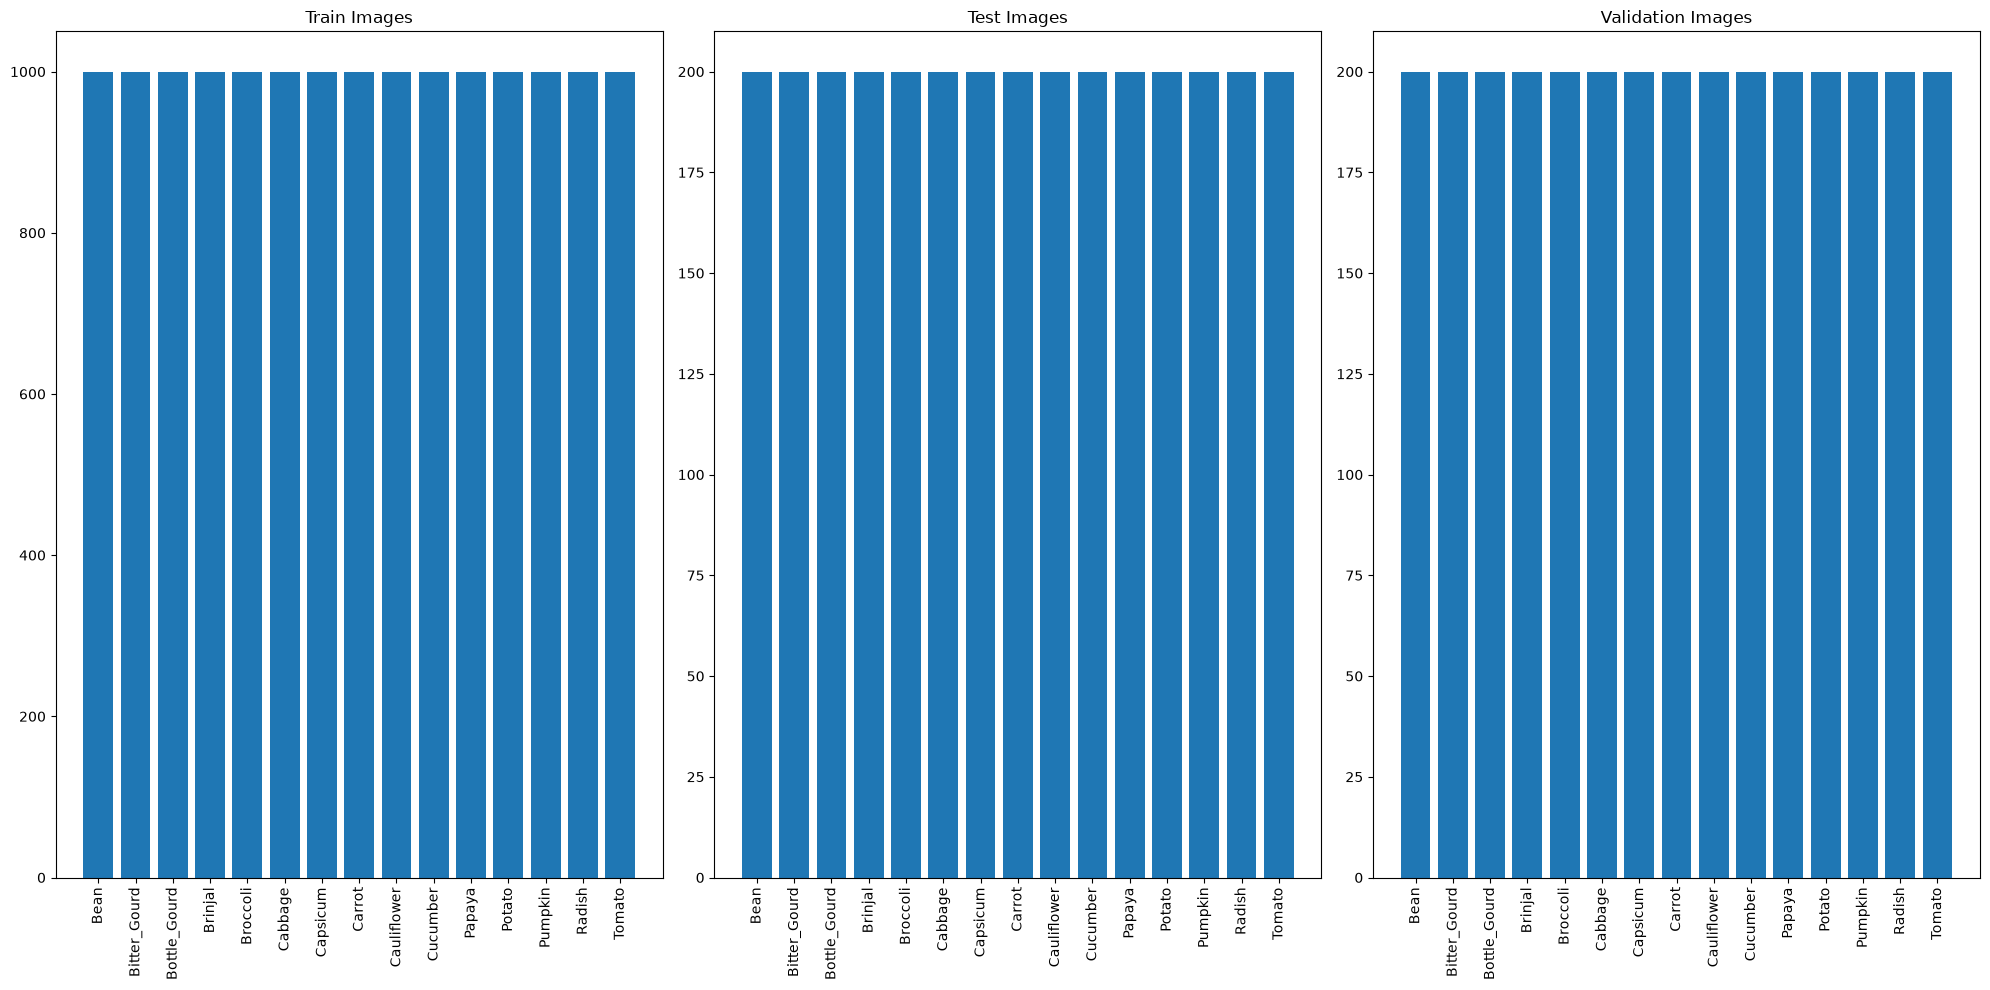

In [9]:
figure, axes = plt.subplots(1, 3, figsize=(20, 10))

axes[0].bar(df_final['Vegetable'], df_final['Train Count'])
axes[0].set_title('Train Images')
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(df_final['Vegetable'], df_final['Test Count'])
axes[1].set_title('Test Images')
axes[1].tick_params(axis='x', rotation=90)

axes[2].bar(df_final['Vegetable'], df_final['Validation Count'])
axes[2].set_title('Validation Images')
axes[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

## Part 6: Image Preprocessing and Augmentation

* Training generator

In [10]:
training_generator = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2,
    rescale=1./255,
    rotation_range=30
)

* validation generator

In [11]:
validation_generator = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

* Test Generator

In [12]:
test_generator = ImageDataGenerator(rescale=1./255)

## Part 7: Load Images Using flow_from_directory

In [13]:
training = training_generator.flow_from_directory(
   train_path,
   target_size = (224,224),
   batch_size = 32,
   class_mode = "categorical",
   seed = 42
)

Found 15000 images belonging to 15 classes.


In [14]:
validation = validation_generator.flow_from_directory(
    validation_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

Found 3000 images belonging to 15 classes.


In [15]:
test  = test_generator.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 15 classes.


In [23]:
img_size = (224, 224)  

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=32,
    label_mode="categorical",   
)

Found 15000 files belonging to 15 classes.
Using 12000 files for training.


In [24]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="categorical",
)

Found 3000 files belonging to 15 classes.
Using 600 files for validation.


## Part 8: Build the CNN Model

In [25]:
model = Sequential()

model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(filters=32, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=64, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=128, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dense(512 , activation='relu'))

Dropout(0.5)

model.add(Dense(15, activation='softmax'))

## Part 9: Compile the Model

In [26]:
model.compile(
    optimizer='adam',
    loss ='categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

## Explain 

* we use softmax in output because we have multi classes in DataSet
* pooling layer help us to reduce Height and width of feature maps
* dropout help us to reduce dependent to a previous neural and prevent overfitting 
* Number of convolutional layers (conv2D)


## Part 10: Train the Model

In [28]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [30]:
history = model.fit(
    train_ds,
    epochs=5,
    validation_data= val_ds,
    callbacks=[early_stop]
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 233s 621ms/step - accuracy: 0.3188 - loss: 7.9643 - val_accuracy: 0.2850 - val_loss: 4.1301
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 265s 708ms/step - accuracy: 0.5975 - loss: 1.3028 - val_accuracy: 0.5050 - val_loss: 1.9992
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 460s 1s/step - accuracy: 0.7690 - loss: 0.7428 - val_accuracy: 0.5600 - val_loss: 2.0535
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 424s 1s/step - accuracy: 0.8450 - loss: 0.5128 - val_accuracy: 0.5517 - val_loss: 2.8799
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 201s 536ms/step - accuracy: 0.8727 - loss: 0.4307 - val_accuracy: 0.5483 - val_loss: 3.4067


## Part 11: Evaluate the Model

In [ ]:
test_loss, test_accuracy = model.evaluate(test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9013 - loss: 0.3075
Test Loss: 0.30748993158340454
Test Accuracy: 0.9013333320617676


## Part 12: Plot Accuracy and Loss Curves

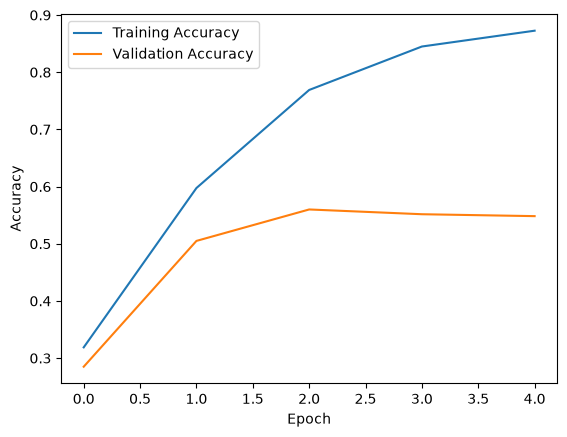

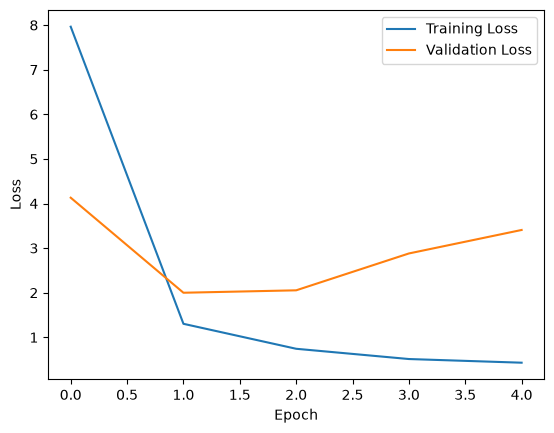

In [31]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()